Loaded Ce/Ce_1/Ce_Sample1_300C.tdms with 12288 wavelengths and 20 spectra
Loaded Ce/Ce_1/Ce_Sample1_350C.tdms with 12288 wavelengths and 20 spectra
Loaded Ce/Ce_1/Ce_Sample1_400C.tdms with 12288 wavelengths and 20 spectra
Loaded Ce/Ce_5/Ce_Sample2_Temp_300C.tdms with 12288 wavelengths and 1 spectra
Loaded Ce/Ce_5/Ce_Sample2_Temp_350C.tdms with 12288 wavelengths and 1 spectra
Loaded Ce/Ce_5/Ce_Sample2_Temp_400C.tdms with 12288 wavelengths and 10 spectra
Loaded Gd/Gd_1/Gd_Sample1_300.tdms with 12288 wavelengths and 2 spectra
Loaded Gd/Gd_1/Gd_Sample1_350.tdms with 12288 wavelengths and 1 spectra
Loaded Gd/Gd_1/Gd_Sample1_400.tdms with 12288 wavelengths and 1 spectra
Loaded Gd/Gd_5/Gd_Sample5_300_3.5delay.tdms with 12288 wavelengths and 11 spectra
Loaded Gd/Gd_5/Gd_Sample5_350_3.5delay.tdms with 12288 wavelengths and 10 spectra
Loaded Gd/Gd_5/Gd_Sample5_400_3.5delay.tdms with 12288 wavelengths and 10 spectra
Loaded 12 files


c:\Users\jackt\Desktop\Git_Repos\LIBS_Viewer\src\LIBS\tdms_loader.py:159: UserWarning: Gd_Sample5_300_3.5delay.tdms: parameters differ between grid locations, using the first: ['Gate Delay (usec)', 'Accumulate', 'Energy', 'Number Of Shots', 'Rep Rate', 'Warmup Energy', '# Of Warmup Shots', 'Setpoint (2)']
  self._load()


,Raw cosine similarity,Raw Pearson r,Derivative cosine similarity,Derivative Pearson r,Manhattan distance
Comparison,,,,,
300 C vs 350 C,0.9934,0.9939,0.9940,0.9940,2.409111e+07
300 C vs 400 C,0.9690,0.9630,0.9271,0.9271,8.034307e+07
350 C vs 400 C,0.9628,0.9559,0.9295,0.9295,1.018691e+08


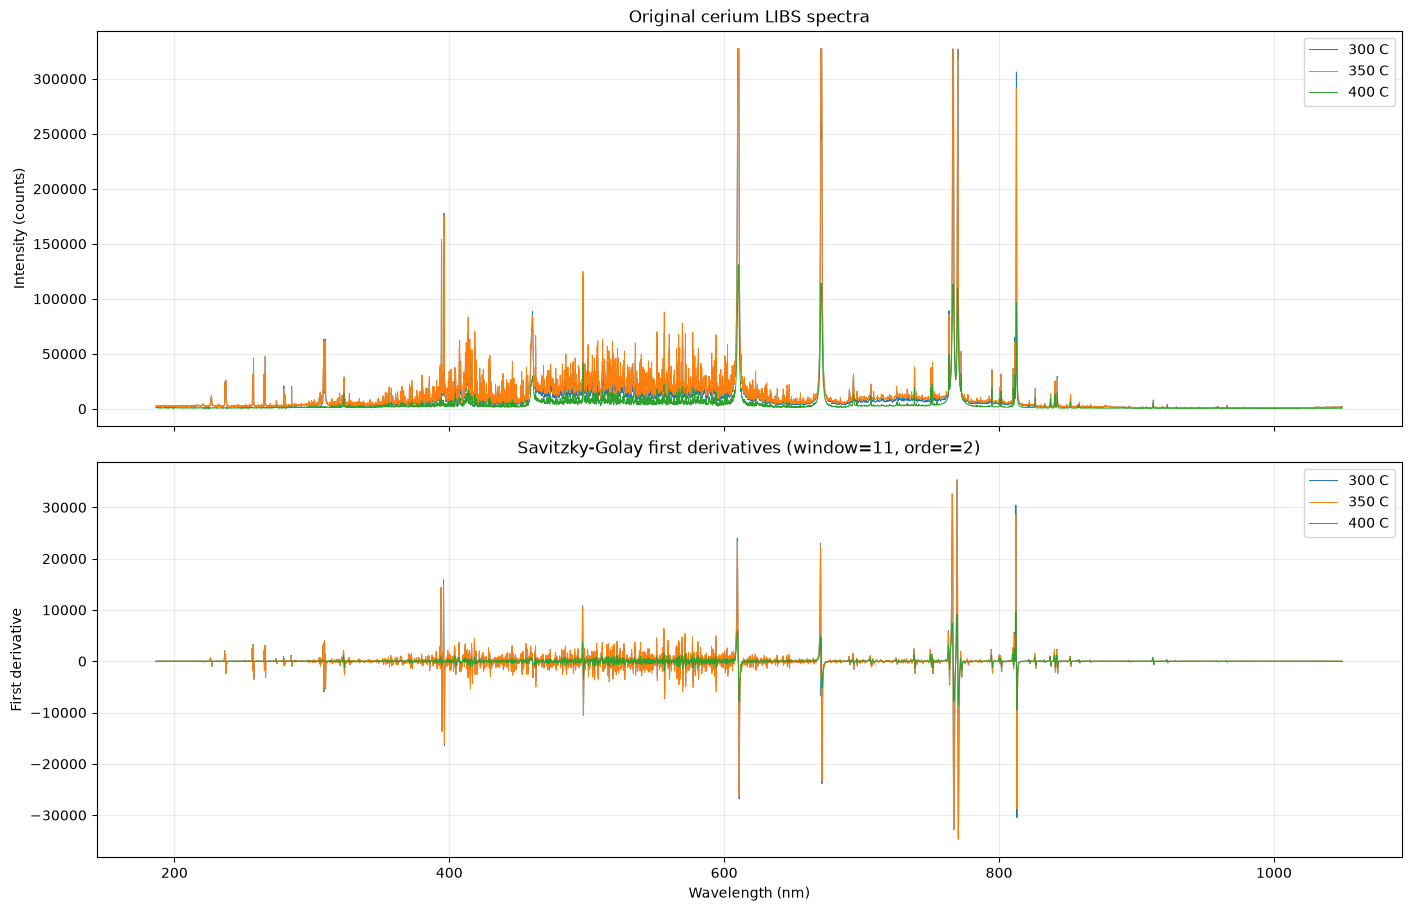

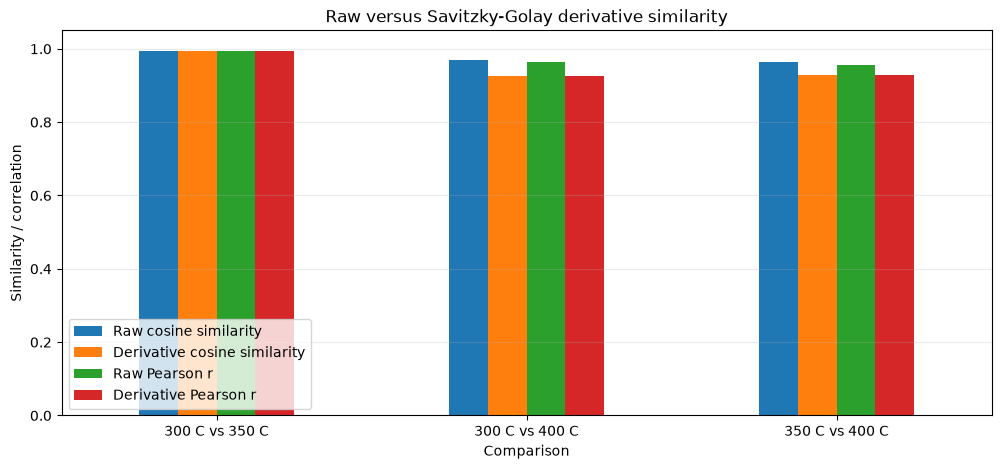

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import savgol_filter
from scipy.spatial.distance import cosine
from scipy.stats import pearsonr

from src.LIBS.tdms_loader import LoadLIBSData

# Load the three cerium temperature levels.
libs = LoadLIBSData(r'data\\libs_data\\Conference_Data', recursive=True)

for filename, f in libs.items():
    print(
        f"Loaded {filename} with "
        f"{f.spectra.shape[0]} wavelengths and "
        f"{f.spectra.shape[1]} spectra"
    )

files = {
    '300 C': 'Ce/Ce_5/Ce_Sample2_Temp_300C.tdms',
    '350 C': 'Ce/Ce_5/Ce_Sample2_Temp_350C.tdms',
    '400 C': 'Ce/Ce_5/Ce_Sample2_Temp_400C.tdms',
}

# Use the first channel for accumulated files. Average the five channels
# from the non-accumulated 400 C file before comparison and plotting.
spectra = {}
for level, key in files.items():
    file_data = libs[key]
    if level == '400 C' and not file_data.accumulated:
        spectra[level] = (file_data.spectra.sum(axis=1) / 5).to_numpy(dtype=float)
    else:
        spectra[level] = file_data.spectra.iloc[:, 0].to_numpy(dtype=float)
wavelengths = libs[next(iter(files.values()))].wavelengths

# Apply a Savitzky-Golay first derivative to suppress slow continuum changes.
window_length = 11
polyorder = 2
derivatives = {
    level: savgol_filter(
        spectrum,
        window_length=window_length,
        polyorder=polyorder,
        deriv=1,
    )
    for level, spectrum in spectra.items()
}

# Compare every temperature pair before and after the derivative treatment.
levels = list(spectra)
comparison_rows = []
for i, level_a in enumerate(levels):
    for level_b in levels[i + 1:]:
        raw_cosine = 1 - cosine(spectra[level_a], spectra[level_b])
        raw_pearson, _ = pearsonr(spectra[level_a], spectra[level_b])
        derivative_cosine = 1 - cosine(derivatives[level_a], derivatives[level_b])
        derivative_pearson, _ = pearsonr(derivatives[level_a], derivatives[level_b])
        
        #TODO: double check this (manhattan) metric, since it is giving the manhattan distance 
        # between all points, not the average distance between the two spectra. 
        # It is also not normalized by the number of points, so it will be larger for longer spectra.

        manhattan_distance = np.sum(np.abs(spectra[level_a] - spectra[level_b])) 

        comparison_rows.append({
            'Comparison': f'{level_a} vs {level_b}',
            'Raw cosine similarity': raw_cosine,
            'Raw Pearson r': raw_pearson,
            'Derivative cosine similarity': derivative_cosine,
            'Derivative Pearson r': derivative_pearson,
            'Manhattan distance': manhattan_distance,
        })

comparison_table = pd.DataFrame(comparison_rows).set_index('Comparison')
print(f'Loaded {len(libs)} files')
display(comparison_table.round(4))

# Plot the original spectra and the baseline-suppressing derivatives.
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, constrained_layout=True)
for level in levels:
    axes[0].plot(wavelengths, spectra[level], linewidth=0.7, label=level)
    axes[1].plot(wavelengths, derivatives[level], linewidth=0.7, label=level)

axes[0].set_title('Original cerium LIBS spectra')
axes[0].set_ylabel('Intensity (counts)')
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].set_title(f'Savitzky-Golay first derivatives (window={window_length}, order={polyorder})')
axes[1].set_xlabel('Wavelength (nm)')
axes[1].set_ylabel('First derivative')
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.show()

# Plot raw versus derivative similarity for each pair.
comparison_table[[
    'Raw cosine similarity',
    'Derivative cosine similarity',
    'Raw Pearson r',
    'Derivative Pearson r',
]].plot(kind='bar', figsize=(12, 5), ylim=(0, 1.05), rot=0)
plt.title('Raw versus Savitzky-Golay derivative similarity')
plt.ylabel('Similarity / correlation')
plt.grid(axis='y', alpha=0.25)
plt.legend(loc='lower left')
plt.show()


In [2]:
# coimparing number of spectra/elements in each of the cerium 300, 350, and 400 to see accumulate or not

sp_300 = libs[files['300 C']].param_table()
print('------------------------------------')
print('300 C Spectra:')
print(sp_300)

sp_350 = libs[files['350 C']].param_table()
print('------------------------------------')
print('350 C Spectra:')
print(sp_350)

sp_400 = libs[files['400 C']].param_table()
print('------------------------------------')
print('400 C Spectra:')
print(sp_400)

Param                          | Value
-------------------------------+------
Gate Delay (usec)              |   3.5
Accumulate                     |     1
Energy                         |    80
Energy Format                  |     0
Number Of Shots                |     5
Rep Rate                       |     1
Warmup Energy                  |    80
# Of Warmup Shots              |    50
Warmup Rep Rate                |    10
Warmup Shots On/Off            |     1
Gas Type (1)                   |     2
Setpoint (1)                   |     0
Gas Type (2)                   |     1
Setpoint (2)                   |     1
Experiment Velocity            |     1
Experiment Acceleration        |    20
Spot Sizes                     |     0
Pre Ablation Delay (Sec)       |     0
Minimum Experiment Delay (Sec) |     1
Washout Delay (Sec)            |     0
Number Of Experiment Passes    |     1
Reverse Pattern Direction      |     0
Pattern Autofocus              |     0
External Trigger Options 

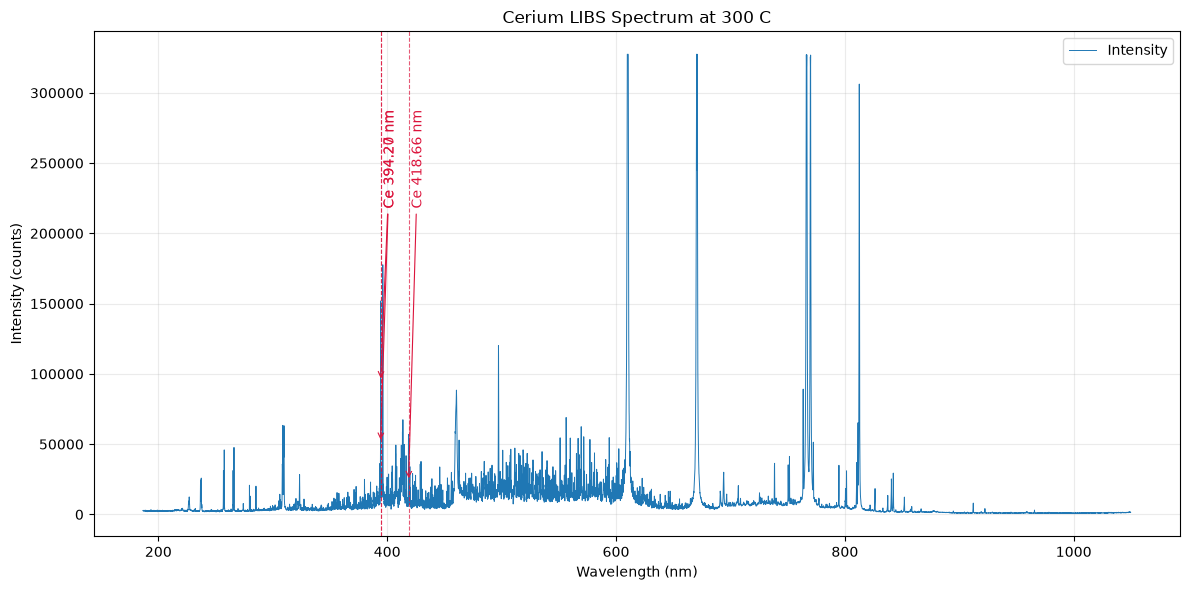

In [3]:
from scipy.signal import find_peaks

spectra_300 = libs[files["300 C"]].spectra.iloc[:, 0].to_numpy(dtype=float)
wavelengths = np.asarray(wavelengths, dtype=float)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(wavelengths, spectra_300, linewidth=0.7, label="Intensity")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity (counts)")
ax.set_title("Cerium LIBS Spectrum at 300 C")
ax.grid(alpha=0.25)

peaks = {
    "Ce 394.20 nm": 394.20,
    "Ce 394.27 nm": 394.27,
    "Ce 418.66 nm": 418.66,
}

y_max = spectra_300.max()

for peak_name, peak_wavelength in peaks.items():
    wavelength_index = np.abs(wavelengths - peak_wavelength).argmin()
    actual_wavelength = wavelengths[wavelength_index]
    intensity = spectra_300[wavelength_index]

    ax.axvline(
        actual_wavelength,
        color="crimson",
        linestyle="--",
        linewidth=0.8,
        alpha=0.7,
    )

    ax.annotate(
        peak_name,
        xy=(actual_wavelength, intensity),
        xytext=(actual_wavelength + 2, y_max * 0.88),
        rotation=90,
        va="top",
        color="crimson",
        arrowprops={
            "arrowstyle": "->",
            "color": "crimson",
            "lw": 0.8,
        },
    )

ax.legend()
plt.tight_layout()
plt.show()

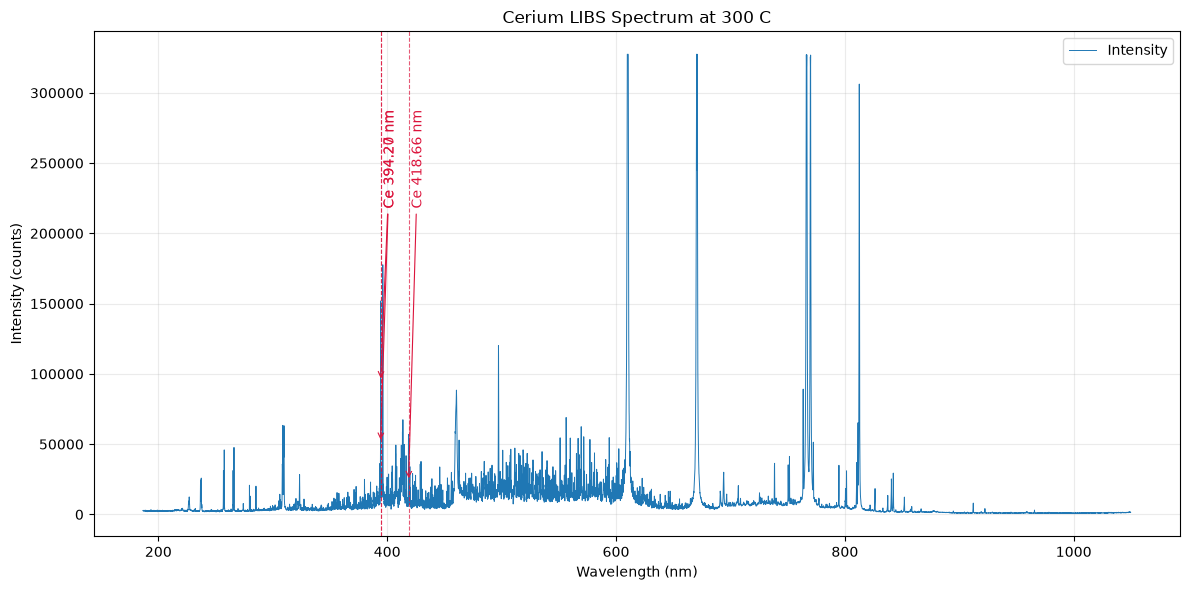

In [4]:
from scipy.signal import find_peaks

spectra_300 = libs[files["300 C"]].spectra.iloc[:, 0].to_numpy(dtype=float)
wavelengths = np.asarray(wavelengths, dtype=float)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(wavelengths, spectra_300, linewidth=0.7, label="Intensity")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Intensity (counts)")
ax.set_title("Cerium LIBS Spectrum at 300 C")
ax.grid(alpha=0.25)

peaks = {
    "Ce 394.20 nm": 394.20,
    "Ce 394.27 nm": 394.27,
    "Ce 418.66 nm": 418.66,
}

y_max = spectra_300.max()

for peak_name, peak_wavelength in peaks.items():
    wavelength_index = np.abs(wavelengths - peak_wavelength).argmin()
    actual_wavelength = wavelengths[wavelength_index]
    intensity = spectra_300[wavelength_index]

    ax.axvline(
        actual_wavelength,
        color="crimson",
        linestyle="--",
        linewidth=0.8,
        alpha=0.7,
    )

    ax.annotate(
        peak_name,
        xy=(actual_wavelength, intensity),
        xytext=(actual_wavelength + 2, y_max * 0.88),
        rotation=90,
        va="top",
        color="crimson",
        arrowprops={
            "arrowstyle": "->",
            "color": "crimson",
            "lw": 0.8,
        },
    )

ax.legend()
plt.tight_layout()
plt.show()

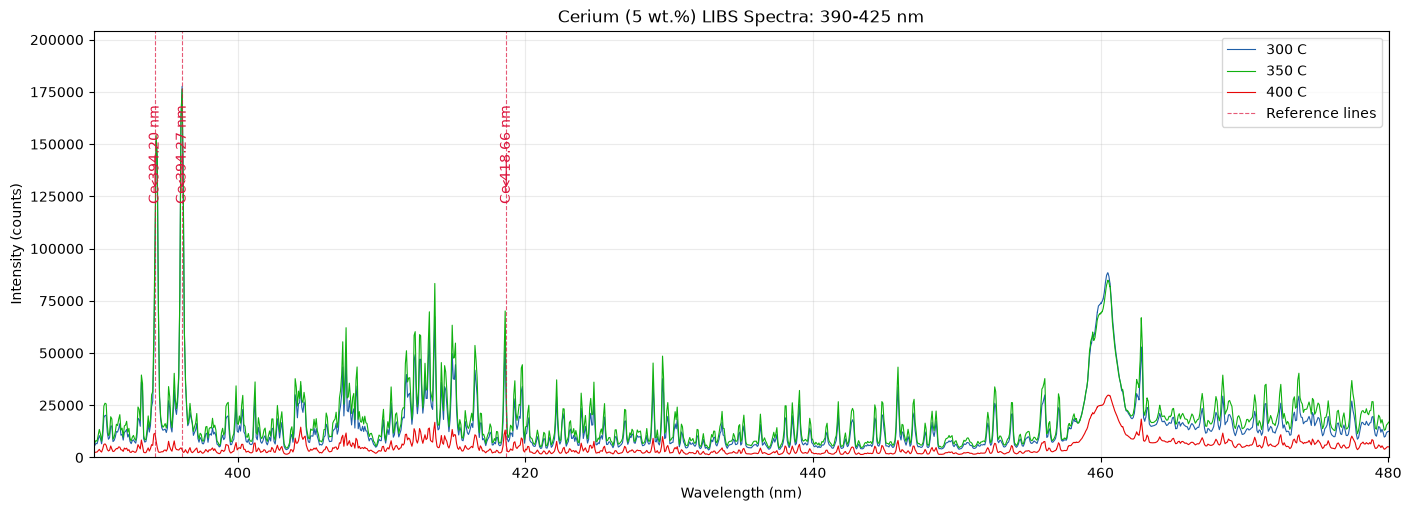

In [5]:
# Overlay all three temperature levels in the selected wavelength window.
wl_range = (390, 480)
lo, hi = sorted(wavelengths[np.argmin(np.abs(wavelengths - x))] for x in wl_range)
in_view = (wavelengths >= lo) & (wavelengths <= hi)

reference_lines = {
    'Ce 394.20 nm': 394.27,
    'Ce 394.27 nm': 396.14,
    'Ce 418.66 nm': 418.66,
}

fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
colors = {'300 C': '#1f5fa8', '350 C': "#10b110", '400 C': "#e60707"}
view_max = max(spectrum[in_view].max() for spectrum in spectra.values())

for level, spectrum in spectra.items():
    ax.plot(
        wavelengths[in_view],
        spectrum[in_view],
        linewidth=0.8,
        color=colors[level],
        label=level,
    )

for reference_number, (peak_name, peak_wavelength) in enumerate(reference_lines.items()):
    wavelength_index = np.abs(wavelengths - peak_wavelength).argmin()
    actual_wavelength = wavelengths[wavelength_index]
    ax.axvline(
        actual_wavelength,
        color='crimson',
        linestyle='--',
        linewidth=0.8,
        alpha=0.7,
        label='Reference lines' if reference_number == 0 else None,
    )
    ax.annotate(
        peak_name,
        xy=(actual_wavelength, view_max * 0.72),
        xytext=(actual_wavelength, view_max * 0.95),
        rotation=90,
        ha='center',
        va='top',
        color='crimson',
        arrowprops={'arrowstyle': '->', 'color': 'crimson', 'lw': 0.8},
    )

ax.set_xlim(lo, hi)
ax.set_ylim(0, view_max * 1.15)
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Intensity (counts)')
ax.set_title('Cerium (5 wt.%) LIBS Spectra: 390-425 nm')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

peak_offset_average = np.mean([
    394.27 - 394.20,  # Ce 394.20 nm
    396.14 - 394.27,  # Ce 394.27 nm
    418.66 - 418.66,  # Ce 418.66 nm
])


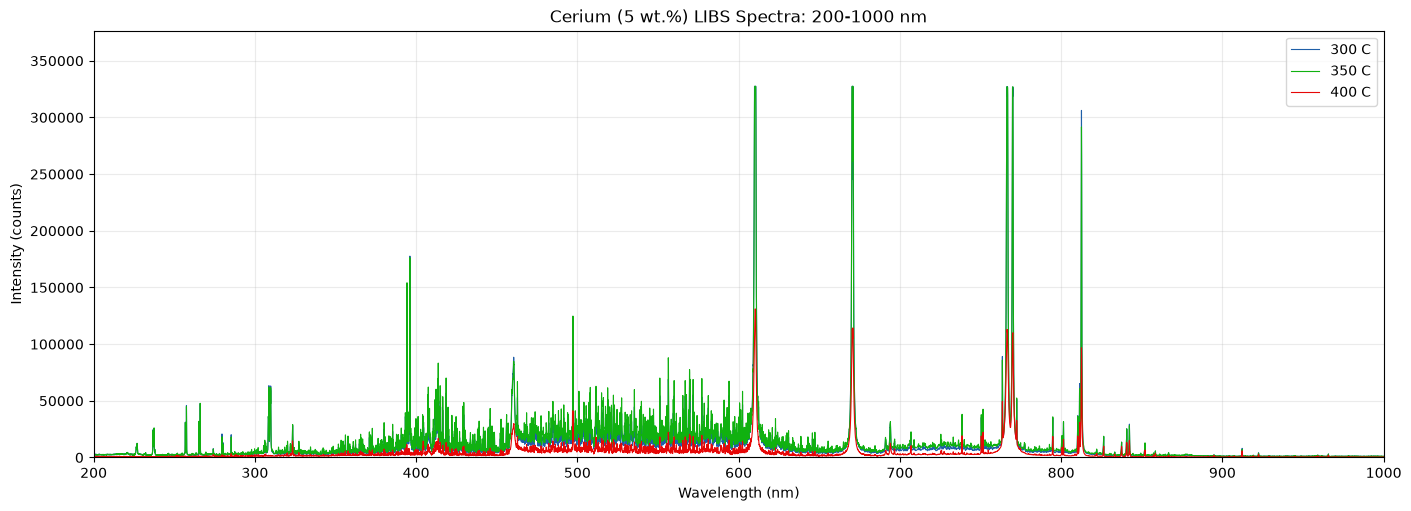

In [7]:
# Overlay all three temperature levels in the selected wavelength window.
wl_range = (200, 1000)
lo, hi = sorted(wavelengths[np.argmin(np.abs(wavelengths - x))] for x in wl_range)
in_view = (wavelengths >= lo) & (wavelengths <= hi)

reference_lines = {
    'Ce 394.20 nm': 394.27,
    'Ce 394.27 nm': 396.14,
    'Ce 418.66 nm': 418.66,
}

fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
colors = {'300 C': '#1f5fa8', '350 C': "#10b110", '400 C': "#e60707"}
view_max = max(spectrum[in_view].max() for spectrum in spectra.values())

for level, spectrum in spectra.items():
    ax.plot(
        wavelengths[in_view],
        spectrum[in_view],
        linewidth=0.8,
        color=colors[level],
        label=level,
    )

# for reference_number, (peak_name, peak_wavelength) in enumerate(reference_lines.items()):
#     wavelength_index = np.abs(wavelengths - peak_wavelength).argmin()
#     actual_wavelength = wavelengths[wavelength_index]
#     ax.axvline(
#         actual_wavelength,
#         color='crimson',
#         linestyle='--',
#         linewidth=0.8,
#         alpha=0.7,
#         label='Reference lines' if reference_number == 0 else None,
#     )
#     ax.annotate(
#         peak_name,
#         xy=(actual_wavelength, view_max * 0.72),
#         xytext=(actual_wavelength, view_max * 0.95),
#         rotation=90,
#         ha='center',
#         va='top',
#         color='crimson',
#         arrowprops={'arrowstyle': '->', 'color': 'crimson', 'lw': 0.8},
#     )

ax.set_xlim(lo, hi)
ax.set_ylim(0, view_max * 1.15)
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Intensity (counts)')
ax.set_title('Cerium (5 wt.%) LIBS Spectra: 200-1000 nm')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

peak_offset_average = np.mean([
    394.27 - 394.20,  # Ce 394.20 nm
    396.14 - 394.27,  # Ce 394.27 nm
    418.66 - 418.66,  # Ce 418.66 nm
])